# Stage 2: Dissatisfaction Classifier (XLM-RoBERTa, multi-label)

Classifies **why** a negative review is negative across 12 categories:
def, dam, perf, pmq, lst, var, mi, auth, pss, del, pack, val.

A review can belong to several categories at once (72% of reviews have 2+), so the model has
one sigmoid output per category and is trained with class-weighted binary cross-entropy.

**Protocol (same design as Stage 1):**
- **Test set:** the negative reviews that are in the Stage 1 held-out test set. They are never
  used for training, so the full cascade (Stage 1 → Stage 2) is evaluated on unseen reviews.
- **Dev set:** all other negative reviews, used for 5-fold multi-label stratified CV (seed 42).
  CV fold scores are used for the hypothesis tests.
- **Final model:** retrained on the full dev set, evaluated once on the test set, and saved
  for the cascade notebook.

**Run order:** both Stage 1 notebooks first (they create `../data/holdout_test_stage1.csv`), then the Stage 2 mBERT notebook, then this one. The last section of this notebook runs the hypothesis tests and needs both models' results.

**Smoke test:** set `SMOKE_TEST = True` to check for errors (200 dev reviews, 1 epoch).
Smoke outputs get a `_smoke` suffix, so they never overwrite or mix with real results.

## 1. Setup

In [1]:
!pip install -q transformers datasets scikit-learn
!pip install -q iterative-stratification


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import gc, os, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import sklearn, transformers
import datasets as hf_datasets
from datasets import Dataset
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from sklearn.metrics import (f1_score, precision_score, recall_score, hamming_loss,
                             accuracy_score, precision_recall_fscore_support,
                             multilabel_confusion_matrix, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

print("transformers:", transformers.__version__)
print("torch:", torch.__version__)
print("sklearn:", sklearn.__version__)
print("datasets:", hf_datasets.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

transformers: 5.22.1
torch: 2.14.0+cu130
sklearn: 1.9.1
datasets: 5.1.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5060


## 2. Config

In [3]:
DATA_PATH = "../data/SentiTaglish_ProductsAndServices_Dissatisfaction_Classification.csv"
STAGE1_DATA_PATH = "../data/SentiTaglish_ProductsAndServices.csv"
HOLDOUT_PATH = "../data/holdout_test_stage1.csv"      # saved by the Stage 1 notebooks
MODELS_DIR = "../models"
RESULTS_DIR = "../results"
os.makedirs(RESULTS_DIR, exist_ok=True)

SMOKE_TEST = False
SMOKE_TEST_SIZE = 200
EPOCHS = 10

SEED = 42
MODEL_NAME = "xlm-roberta-base"
TAG = MODEL_NAME.split("/")[-1]
MAX_LENGTH = 128
LEARNING_RATE = 2e-5
BATCH_SIZE = 8
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
MAX_POS_WEIGHT = 10.0
PREDICTION_THRESHOLD = 0.5   # sigmoid output at or above this counts as a positive label
N_FOLDS = 5
NEGATIVE_CODE = 1            # Stage 1 sentiment code for "negative"

CATEGORY_COLUMNS = ["def", "dam", "perf", "pmq", "lst", "var", "mi",
                    "auth", "pss", "del", "pack", "val"]
NUM_LABELS = len(CATEGORY_COLUMNS)
ID2LABEL = {i: name for i, name in enumerate(CATEGORY_COLUMNS)}
LABEL2ID = {name: i for i, name in enumerate(CATEGORY_COLUMNS)}

epochs = 1 if SMOKE_TEST else EPOCHS
SUFFIX = "_smoke" if SMOKE_TEST else ""

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Model: {MODEL_NAME} | device: {device} | epochs: {epochs} | smoke test: {SMOKE_TEST}")
if device == "cpu":
    print("WARNING: no GPU detected.")

Model: xlm-roberta-base | device: cuda | epochs: 10 | smoke test: False


## 3. Text cleaning (identical to Stage 1)

In [4]:
SPELLING_MAP = {
    "d2": "dito", "dto": "dito",
    "un": "yun",
    "sya": "siya", "cya": "siya",
    "nde": "hindi", "hnd": "hindi",
    "wla": "wala", "wlang": "walang",
    "eto": "ito",
    "pde": "pwede", "pwd": "pwede",
    "gud": "good",
    "thnx": "thanks", "tnx": "thanks",
    "salamt": "salamat",
}

_REPEATED_CHAR = re.compile(r"(.)\1{2,}")
_WHITESPACE = re.compile(r"\s+")

def clean_text(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = text.lower()
    text = _REPEATED_CHAR.sub(r"\1\1", text)
    tokens = text.split()
    tokens = [SPELLING_MAP.get(t, t) for t in tokens]
    text = " ".join(tokens)
    text = _WHITESPACE.sub(" ", text).strip()
    return text

print(clean_text("SOBRAAAA panget ng quality, sira agad!!"))

sobraa panget ng quality, sira agad!!


## 4. Load data and split into dev / test

The test set is the negative reviews in the Stage 1 held-out test set, matched by cleaned
review text. Every Stage 2 row whose text matches a held-out negative goes to the test set,
so no held-out review (or an exact duplicate of one) is ever trained on.

In [5]:
df = pd.read_csv(DATA_PATH)
if "review" not in df.columns and "a" in df.columns:
    df = df.rename(columns={"a": "review"})
missing_cols = [c for c in CATEGORY_COLUMNS if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing category columns: {missing_cols}. Found: {list(df.columns)}")

df["review_clean"] = df["review"].apply(clean_text)
df = df[df["review_clean"] != ""].reset_index(drop=True)
print(f"Stage 2 dataset: {len(df)} reviews")

# Stage 1 held-out negatives (row_id = row position in the Stage 1 CSV, as in Stage 1)
s1 = pd.read_csv(STAGE1_DATA_PATH)
s1["row_id"] = np.arange(len(s1))
holdout_ids = set(pd.read_csv(HOLDOUT_PATH)["row_id"])
s1_test_neg = s1[s1["row_id"].isin(holdout_ids) & (s1["sentiment"] == NEGATIVE_CODE)].copy()
s1_test_neg["review_clean"] = s1_test_neg["review"].apply(clean_text)
text_to_row_id = dict(zip(s1_test_neg["review_clean"], s1_test_neg["row_id"]))

df["in_holdout"] = df["review_clean"].isin(text_to_row_id)
dev_df = df[~df["in_holdout"]].reset_index(drop=True)
test_df = df[df["in_holdout"]].reset_index(drop=True)
test_df["stage1_row_id"] = test_df["review_clean"].map(text_to_row_id)

n_found = test_df["review_clean"].nunique()
print(f"Stage 1 held-out negatives: {len(s1_test_neg)} | found in Stage 2 data: {n_found}")
if n_found < len(s1_test_neg):
    print(f"WARNING: {len(s1_test_neg) - n_found} held-out negatives have no matching Stage 2 row.")
assert len(test_df) > 0, "No held-out negatives matched. Check HOLDOUT_PATH and STAGE1_DATA_PATH."

if SMOKE_TEST:
    dev_df = dev_df.sample(min(len(dev_df), SMOKE_TEST_SIZE), random_state=SEED).reset_index(drop=True)
    print(f"[SMOKE TEST] dev reduced to {len(dev_df)} reviews")

Y_dev = dev_df[CATEGORY_COLUMNS].values.astype(float)
Y_test = test_df[CATEGORY_COLUMNS].values.astype(float)
print(f"\nDev (CV pool): {len(dev_df)} | Test: {len(test_df)}")

dist = pd.DataFrame({
    "dev_count": Y_dev.sum(axis=0).astype(int),
    "test_count": Y_test.sum(axis=0).astype(int),
}, index=CATEGORY_COLUMNS)
dist["dev_%"] = (100 * dist["dev_count"] / len(dev_df)).round(1)
dist["test_%"] = (100 * dist["test_count"] / len(test_df)).round(1)
print(dist.to_string())

Stage 2 dataset: 3408 reviews
Stage 1 held-out negatives: 511 | found in Stage 2 data: 511

Dev (CV pool): 2897 | Test: 511
      dev_count  test_count  dev_%  test_%
def         613          97   21.2    19.0
dam         412          90   14.2    17.6
perf        337          55   11.6    10.8
pmq         619         123   21.4    24.1
lst         710         112   24.5    21.9
var         754         124   26.0    24.3
mi          326          53   11.3    10.4
auth         53           8    1.8     1.6
pss        1076         192   37.1    37.6
del         183          41    6.3     8.0
pack        211          40    7.3     7.8
val         412          62   14.2    12.1


## 5. Helpers (training and metrics)

In [6]:
class WeightedBCETrainer(Trainer):
    def __init__(self, *args, pos_weight=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight = pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight)(outputs.logits, labels.float())
        return (loss, outputs) if return_outputs else loss


def make_ds(tok, texts, labels):
    enc = tok(list(texts), truncation=True, max_length=MAX_LENGTH)
    enc["labels"] = labels.tolist()
    return Dataset.from_dict(enc)


def train_model(texts, labels, output_dir):
    """Trains one model with the study's fixed settings. Returns (trainer, tokenizer)."""
    set_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS, problem_type="multi_label_classification",
        id2label=ID2LABEL, label2id=LABEL2ID,
    )
    num_pos = labels.sum(axis=0)
    pw = np.clip((len(labels) - num_pos) / np.clip(num_pos, 1, None), None, MAX_POS_WEIGHT)
    pos_weight = torch.tensor(pw, dtype=torch.float32, device=device)

    total_steps = int(np.ceil(len(labels) / BATCH_SIZE)) * epochs
    args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=32,
        num_train_epochs=epochs,
        warmup_steps=int(WARMUP_RATIO * total_steps),
        weight_decay=WEIGHT_DECAY,
        save_strategy="no",
        seed=SEED,
        report_to="none",
    )
    trainer = WeightedBCETrainer(
        model=model, args=args, train_dataset=make_ds(tokenizer, texts, labels),
        data_collator=DataCollatorWithPadding(tokenizer), pos_weight=pos_weight,
    )
    trainer.train()
    return trainer, tokenizer


def predict_probs(trainer, tokenizer, texts, labels):
    out = trainer.predict(make_ds(tokenizer, texts, labels))
    return 1 / (1 + np.exp(-out.predictions))


def score_multilabel(y, p):
    """All Ch. III metrics for multi-label output (y, p: 0/1 arrays of shape [n, 12])."""
    s = {
        "subset_accuracy": accuracy_score(y, p),
        "hamming_loss": hamming_loss(y, p),
    }
    for avg in ["macro", "micro", "weighted"]:
        s[f"{avg}_f1"] = f1_score(y, p, average=avg, zero_division=0)
        s[f"{avg}_precision"] = precision_score(y, p, average=avg, zero_division=0)
        s[f"{avg}_recall"] = recall_score(y, p, average=avg, zero_division=0)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average=None, zero_division=0)
    for i, cat in enumerate(CATEGORY_COLUMNS):
        s[f"precision_{cat}"] = pr[i]
        s[f"recall_{cat}"] = rc[i]
        s[f"f1_{cat}"] = f1[i]
    return s


MAIN_COLS = ["subset_accuracy", "hamming_loss", "macro_f1", "micro_f1", "weighted_f1",
             "macro_precision", "micro_precision", "macro_recall", "micro_recall"]

## 6. 5-fold cross-validation on the dev set

Same folds for both models (MultilabelStratifiedKFold, seed 42). Fold sizes are saved with
the scores so the hypothesis test can check that both models used identical folds.

In [7]:
mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
rows = []

for fold, (tr, va) in enumerate(mskf.split(np.zeros(len(dev_df)), Y_dev)):
    print(f"\n=== Fold {fold + 1}/{N_FOLDS} | train {len(tr)} | val {len(va)} ===")
    trainer, tokenizer = train_model(dev_df["review_clean"].iloc[tr], Y_dev[tr],
                                     f"{MODELS_DIR}/stage2_tmp/{TAG}_fold{fold}")
    probs = predict_probs(trainer, tokenizer, dev_df["review_clean"].iloc[va], Y_dev[va])
    p = (probs >= PREDICTION_THRESHOLD).astype(int)

    rows.append({"model": TAG, "fold": fold, "n_train": len(tr), "n_val": len(va),
                 **score_multilabel(Y_dev[va].astype(int), p)})
    pd.DataFrame(rows).to_csv(f"{RESULTS_DIR}/stage2_{TAG}_folds_partial{SUFFIX}.csv", index=False)

    del trainer
    gc.collect()
    torch.cuda.empty_cache()

cv = pd.DataFrame(rows)
cv.to_csv(f"{RESULTS_DIR}/stage2_{TAG}_folds{SUFFIX}.csv", index=False)

summary = cv.drop(columns=["model", "fold", "n_train", "n_val"]).agg(["mean", "std"]).T.round(4)
print("\nCV summary (main metrics):")
print(summary.loc[MAIN_COLS].to_string())
print("\nCV per-category F1:")
print(summary.loc[[f"f1_{c}" for c in CATEGORY_COLUMNS]].to_string())


=== Fold 1/5 | train 2317 | val 580 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
500,0.935160
1000,0.591886
1500,0.427826
2000,0.326893
2500,0.258392



=== Fold 2/5 | train 2320 | val 577 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (11 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
500,0.939939
1000,0.603778
1500,0.436289
2000,0.326991
2500,0.261609



CV summary (main metrics):
                   mean     std
subset_accuracy  0.4018  0.0194
hamming_loss     0.0830  0.0038
macro_f1         0.7363  0.0203
micro_f1         0.7693  0.0113
weighted_f1      0.7709  0.0115
macro_precision  0.6813  0.0159
micro_precision  0.7071  0.0077
macro_recall     0.8083  0.0280
micro_recall     0.8437  0.0175

CV per-category F1:
           mean     std
f1_def   0.7799  0.0274
f1_dam   0.7253  0.0481
f1_perf  0.6708  0.0262
f1_pmq   0.7124  0.0133
f1_lst   0.7135  0.0396
f1_var   0.8782  0.0254
f1_mi    0.7906  0.0218
f1_auth  0.4321  0.1090
f1_pss   0.8138  0.0138
f1_del   0.7549  0.0664
f1_pack  0.7602  0.0393
f1_val   0.8039  0.0448


## 7. Final model: train on the full dev set, evaluate once on the test set

The saved model in `../models/stage2_<model>_final` is the one used by the cascade notebook.

In [8]:
final_dir = f"{MODELS_DIR}/stage2_{TAG}_final{SUFFIX}"
trainer, tokenizer = train_model(dev_df["review_clean"], Y_dev, f"{MODELS_DIR}/stage2_tmp/{TAG}_final")
trainer.save_model(final_dir)
tokenizer.save_pretrained(final_dir)
print(f"Saved final model to {final_dir}")

test_probs = predict_probs(trainer, tokenizer, test_df["review_clean"], Y_test)
test_pred = (test_probs >= PREDICTION_THRESHOLD).astype(int)
y_test = Y_test.astype(int)

test_scores = score_multilabel(y_test, test_pred)
pd.DataFrame([{"model": TAG, "n_test": len(test_df), **test_scores}]).to_csv(
    f"{RESULTS_DIR}/stage2_{TAG}_test{SUFFIX}.csv", index=False)

# Per-review predictions
pred_out = test_df[["stage1_row_id", "review"]].copy()
for i, cat in enumerate(CATEGORY_COLUMNS):
    pred_out[f"true_{cat}"] = y_test[:, i]
    pred_out[f"pred_{cat}"] = test_pred[:, i]
    pred_out[f"prob_{cat}"] = test_probs[:, i].round(4)
pred_out.to_csv(f"{RESULTS_DIR}/stage2_{TAG}_test_predictions{SUFFIX}.csv", index=False)

print("\nHeld-out test results (main metrics):")
print(pd.Series(test_scores)[MAIN_COLS].round(4).to_string())

per_cat = pd.DataFrame({
    "support": y_test.sum(axis=0),
    "precision": [test_scores[f"precision_{c}"] for c in CATEGORY_COLUMNS],
    "recall": [test_scores[f"recall_{c}"] for c in CATEGORY_COLUMNS],
    "f1": [test_scores[f"f1_{c}"] for c in CATEGORY_COLUMNS],
}, index=CATEGORY_COLUMNS)
print("\nHeld-out test, per category:")
print(per_cat.round(4).to_string())

del trainer
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
500,0.941771
1000,0.617856
1500,0.452756
2000,0.340952
2500,0.272730
3000,0.220775
3500,0.185644


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved final model to ../models/stage2_xlm-roberta-base_final



Held-out test results (main metrics):
subset_accuracy    0.4814
hamming_loss       0.0695
macro_f1           0.7642
micro_f1           0.7998
weighted_f1        0.8015
macro_precision    0.7174
micro_precision    0.7524
macro_recall       0.8205
micro_recall       0.8536

Held-out test, per category:
      support  precision  recall      f1
def        97     0.6975  0.8557  0.7685
dam        90     0.7579  0.8000  0.7784
perf       55     0.5909  0.7091  0.6446
pmq       123     0.7183  0.8293  0.7698
lst       112     0.6835  0.8482  0.7570
var       124     0.8984  0.9274  0.9127
mi         53     0.7273  0.9057  0.8067
auth        8     0.4545  0.6250  0.5263
pss       192     0.8421  0.9167  0.8778
del        41     0.7143  0.7317  0.7229
pack       40     0.7955  0.8750  0.8333
val        62     0.7286  0.8226  0.7727


### Per-category confusion matrices (held-out test)

One 2x2 matrix per category: true/false positives and negatives for "has this category".

category  tp  fp  fn  tn
     def  83  36  14 378
     dam  72  23  18 398
    perf  39  27  16 429
     pmq 102  40  21 348
     lst  95  44  17 355
     var 115  13   9 374
      mi  48  18   5 440
    auth   5   6   3 497
     pss 176  33  16 286
     del  30  12  11 458
    pack  35   9   5 462
     val  51  19  11 430


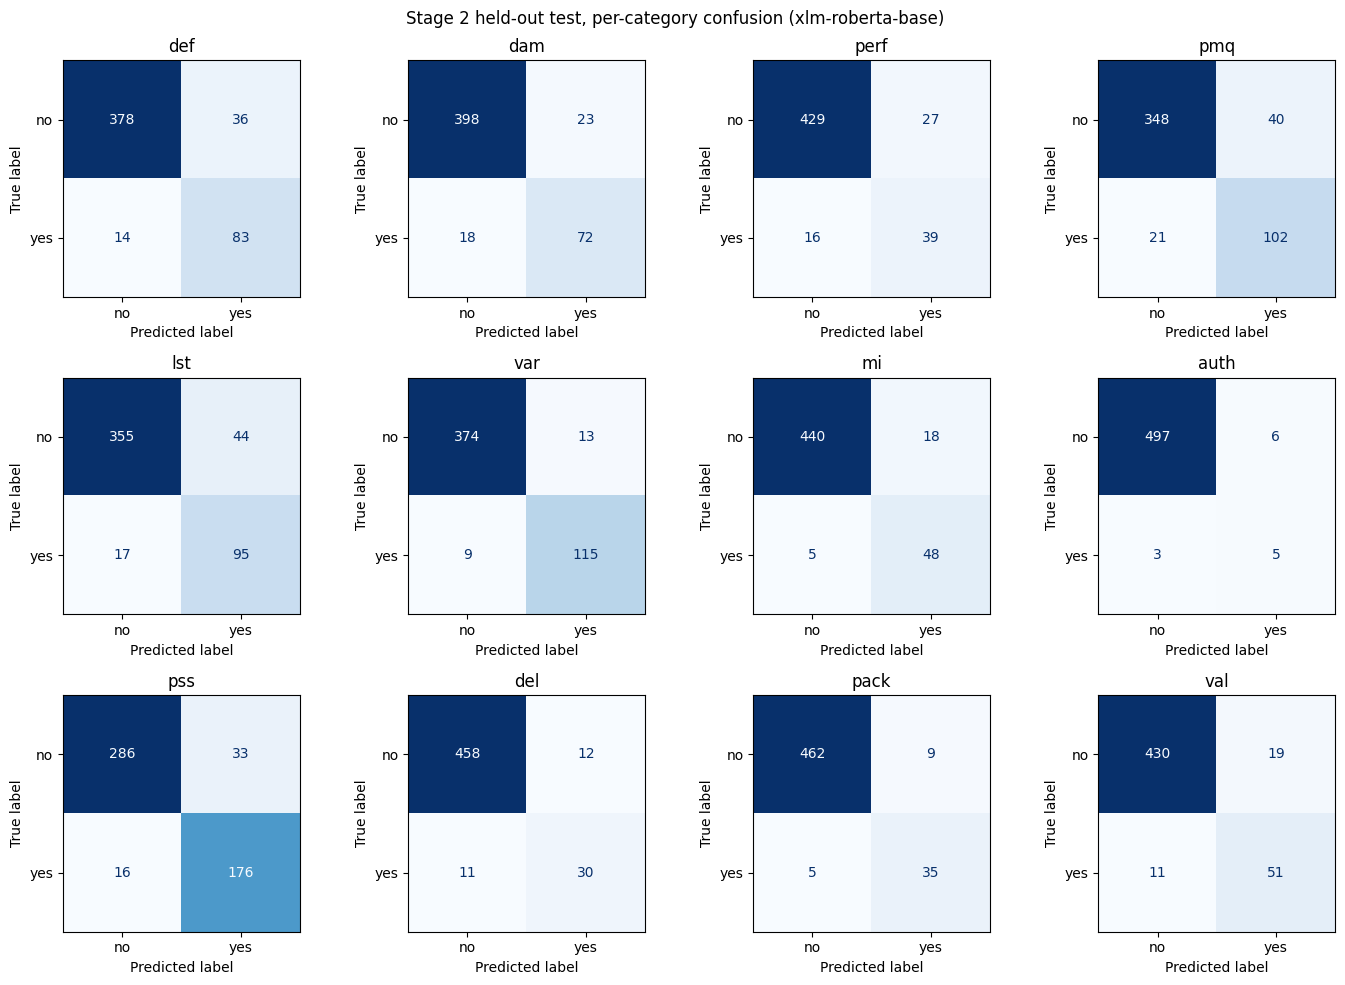

In [9]:
def per_label_confusion(y, p):
    mcm = multilabel_confusion_matrix(y, p)
    return pd.DataFrame(
        [{"category": c, "tp": m[1, 1], "fp": m[0, 1], "fn": m[1, 0], "tn": m[0, 0]}
         for c, m in zip(CATEGORY_COLUMNS, mcm)]
    ), mcm

conf_df, mcm = per_label_confusion(y_test, test_pred)
conf_df.to_csv(f"{RESULTS_DIR}/stage2_{TAG}_test_confusion{SUFFIX}.csv", index=False)
print(conf_df.to_string(index=False))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, cat, m in zip(axes.ravel(), CATEGORY_COLUMNS, mcm):
    ConfusionMatrixDisplay(m, display_labels=["no", "yes"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(cat)
fig.suptitle(f"Stage 2 held-out test, per-category confusion ({TAG})")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/stage2_{TAG}_test_confusion{SUFFIX}.png", dpi=200)
plt.show()

## 8. Hypothesis tests: XLM-R vs mBERT (H02, H03)

Corrected resampled paired t-test (Nadeau & Bengio, 2003) on the 5 CV fold scores, the same
test used in Stage 1. Macro-F1 is the primary metric; subset accuracy (exact match) is the
multi-label "accuracy" for H03. For hamming loss, lower is better, so a negative t favors XLM-R.
Per-category F1 tests use the Holm correction across the 12 categories (Holm, 1979).

Run this after **both** Stage 2 notebooks have finished their full (non-smoke) runs.

In [10]:
from scipy import stats

def corrected_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return t, p

def holm(pvals):
    p = np.asarray(pvals); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[idx]))
        adj[idx] = running
    return adj

a = pd.read_csv(f"{RESULTS_DIR}/stage2_xlm-roberta-base_folds.csv").sort_values("fold").reset_index(drop=True)
b = pd.read_csv(f"{RESULTS_DIR}/stage2_bert-base-multilingual-uncased_folds.csv").sort_values("fold").reset_index(drop=True)
assert len(a) == len(b) == N_FOLDS, "Each model needs 5 full folds"
assert (a["n_val"].values == b["n_val"].values).all(), "Models were not evaluated on the same folds"
N_TRAIN, N_TEST = a["n_train"].mean(), a["n_val"].mean()
print(f"Per fold: n_train = {N_TRAIN:.0f}, n_val = {N_TEST:.0f}\n")

main = []
for m in ["macro_f1", "subset_accuracy", "micro_f1", "weighted_f1", "hamming_loss"]:
    t, p = corrected_ttest(a[m], b[m], N_TRAIN, N_TEST)
    main.append({"metric": m, "xlmr_mean": a[m].mean(), "mbert_mean": b[m].mean(),
                 "t": t, "p": p, "significant": p < 0.05})
main = pd.DataFrame(main)
main.to_csv(f"{RESULTS_DIR}/stage2_hypothesis_tests.csv", index=False)
print("Overall metrics:")
print(main.round(4).to_string(index=False))

per = []
for c in CATEGORY_COLUMNS:
    t, p = corrected_ttest(a[f"f1_{c}"], b[f"f1_{c}"], N_TRAIN, N_TEST)
    per.append({"category": c, "xlmr_f1": a[f"f1_{c}"].mean(), "mbert_f1": b[f"f1_{c}"].mean(), "t": t, "p": p})
per = pd.DataFrame(per)
per["p_holm"] = holm(per["p"])
per["significant"] = per["p_holm"] < 0.05
per.to_csv(f"{RESULTS_DIR}/stage2_per_category_tests.csv", index=False)
print("\nPer-category F1 (Holm-corrected):")
print(per.round(4).to_string(index=False))

Per fold: n_train = 2318, n_val = 579

Overall metrics:
         metric  xlmr_mean  mbert_mean       t      p  significant
       macro_f1     0.7363      0.7150  2.5161 0.0656        False
subset_accuracy     0.4018      0.3528  2.6270 0.0584        False
       micro_f1     0.7693      0.7349  6.5431 0.0028         True
    weighted_f1     0.7709      0.7353  6.3810 0.0031         True
   hamming_loss     0.0830      0.0942 -4.6198 0.0099         True

Per-category F1 (Holm-corrected):
category  xlmr_f1  mbert_f1       t      p  p_holm  significant
     def   0.7799    0.7301  3.6901 0.0210  0.2312        False
     dam   0.7253    0.7075  1.0386 0.3576  0.7153        False
    perf   0.6708    0.6108  2.0173 0.1138  0.6898        False
     pmq   0.7124    0.6840  5.8260 0.0043  0.0519        False
     lst   0.7135    0.6811  1.9058 0.1294  0.6898        False
     var   0.8782    0.8538  1.6093 0.1828  0.6898        False
      mi   0.7906    0.7054  2.8909 0.0445  0.4452        F

## 9. Both models on the held-out test set

In [11]:
test_table = pd.concat([
    pd.read_csv(f"{RESULTS_DIR}/stage2_bert-base-multilingual-uncased_test.csv"),
    pd.read_csv(f"{RESULTS_DIR}/stage2_xlm-roberta-base_test.csv"),
], ignore_index=True)
test_table.to_csv(f"{RESULTS_DIR}/stage2_all_models_test.csv", index=False)
print("Overall:")
print(test_table[["model"] + MAIN_COLS].round(4).to_string(index=False))
print("\nPer-category F1:")
print(test_table[["model"] + [f"f1_{c}" for c in CATEGORY_COLUMNS]].round(4).to_string(index=False))

Overall:
                         model  subset_accuracy  hamming_loss  macro_f1  micro_f1  weighted_f1  macro_precision  micro_precision  macro_recall  micro_recall
bert-base-multilingual-uncased           0.3542        0.0908    0.7013    0.7406       0.7396           0.6676           0.6913        0.7454        0.7974
              xlm-roberta-base           0.4814        0.0695    0.7642    0.7998       0.8015           0.7174           0.7524        0.8205        0.8536

Per-category F1:
                         model  f1_def  f1_dam  f1_perf  f1_pmq  f1_lst  f1_var  f1_mi  f1_auth  f1_pss  f1_del  f1_pack  f1_val
bert-base-multilingual-uncased  0.7290  0.7684   0.6066  0.6943  0.6805  0.8425 0.6723   0.5000  0.8238  0.6479   0.7381  0.7121
              xlm-roberta-base  0.7685  0.7784   0.6446  0.7698  0.7570  0.9127 0.8067   0.5263  0.8778  0.7229   0.8333  0.7727
